# 12 - Core Calibration and the Digital Core

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/12_core_calibration_and_digital_core.ipynb)

**Part B - Petrophys Curriculum**

Wireline logs are *indirect* measurements. A neutron tool counts hydrogen, a
density tool counts back-scattered gamma rays - neither one *is* porosity. The
ground truth against which every log interpretation is ultimately judged is the
**core**: a physical cylinder of rock brought to surface and measured in the
laboratory.

This lesson has four parts:

1. **Core-to-log calibration** - tie laboratory helium porosity and Klinkenberg
   permeability to the logs, quantify the mismatch ($R^2$, bias, RMSE), and fit a
   **poro-perm transform** so we can predict permeability everywhere the core did
   not sample.
2. **Rock typing on the cored interval** - cluster real wireline logs into
   **electrofacies** with weighted K-means (`DigitalCoreFacies`), fingerprint
   each cluster with per-facies statistics, and read the clusters on a
   density-neutron cross-plot.
3. **Geochemistry from spectral gamma** - read thorium and uranium logs for
   depositional environment (the Th/U ratio), and build a thorium clay
   indicator that shows where uranium corrupts the GR clay volume.
4. **A second well's core** - repeat the calibration on another cored well,
   repair its core-to-log depth tie, and test whether a poro-perm transform
   carries from one well to the other.

Parts 1 and 2 use the cored well **30/6-5** (Oseberg Øst, Norwegian North Sea). Parts 3 and 4
use **25/5-1** (Frøy, North Sea), which carries spectral gamma and core plugs.
Sections 2.2-2.4 use **EDE-01** (Netherlands): XRF, merged grain size,
probe permeability and scanner strength from EpsLog, alongside matching
composite well logs from NLOG.NL. The examples call the library's digital-core
readers and elastic-property calculator. Part 3 demonstrates spectral
geochemistry measured downhole on 25/5-1.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

By the end of this lesson you will be able to:

- Build a `CoreData` container directly from a cored well with
  `core_data` (from `petrophys.interpretation.core_analysis`).
- Calibrate a log-derived porosity against core with `calibrate_porosity`, and
  read the calibration statistics off a `CalibrationResult`.
- Fit a linear porosity correction (`fit_porosity_correction`) and a poro-perm
  transform (`fit_poro_perm`), apply the transform to the log, and
  judge where the prediction is supported by core and where it extrapolates.
- Cluster wireline logs over the cored interval into electrofacies with
  `DigitalCoreFacies` / `FaciesResult`, and produce a per-facies statistics
  table.
- Check processed spectral gamma curves for units, coverage and plausibility
  (including held readings at the bottom of a logging run, with
  `find_held_readings`), then interpret them with `interpret_spectral_gamma`.
- Read the Th/U ratio against the standard thresholds for depositional
  environment (`classify_th_u_environment`), and compare a thorium clay
  indicator (`thorium_clay_index`) with the GR clay volume to locate where
  uranium biases it.
- Diagnose a core-to-log depth offset with `find_core_depth_shift`, and test
  whether a poro-perm transform carries from one well to another.
- Load EDE-01 core-scanner measurements, normalize XRF concentration units,
  classify grain size, compare probe permeability and calculate dynamic
  elastic properties from matching well logs.


## Why this matters

Every deterministic petrophysical answer - porosity, saturation, net pay,
volumes - inherits the systematic error of the logs it was built from. Core
calibration is how we *anchor* those logs to reality:

- **Porosity** measured by a density tool depends on an assumed matrix density.
  Get the grain density wrong and every porosity is biased. Core helium porosity
  fixes the tie point.
- **Permeability** is never measured by wireline; it is *always* a correlation.
  A poro-perm transform fitted to core plugs is the standard way to propagate a
  handful of lab measurements to the full log.
- **Clay volume** is usually read from GR, on the assumption that all
  radioactivity comes from clay. A spectral gamma log splits GR into potassium,
  thorium and uranium, which shows when that assumption fails.

The **digital core** pushes this further. Instead of one plug every ~30 cm,
modern core scanners deliver *continuous* millimetre-to-centimetre logs of grain
size, elemental chemistry, strength, and colour. Clustering these into facies
gives a rock-typing scheme that is fully data-driven and reproducible - the
kind of product commercial core-scanning services deliver.

Finally, calibrations and transforms are built in the wells that have core and
then reused in wells that do not. Checking them against a second cored well is
how you find out whether that reuse is safe.

> **Units convention.** In `petrophys`, porosity and saturation are stored as
> **fractions (v/v, 0-1)**, permeability in **mD**, grain/bulk density in
> **g/cm3**, thorium and uranium in **ppm**, and potassium in **%**.

### Prerequisites

Assumes the Part A clay volume, porosity and permeability lessons (03, 04, 08).
Part 2 uses `DigitalCoreFacies`, which needs **scikit-learn** for K-means
clustering. Install it with the machine-learning extra:

```bash
pip install "petrophys[ml]"
```

Parts 1, 3 and 4 run with the base installation.

In [2]:
import warnings

# Keep warning messages visible without local filesystem paths.
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"
import numpy as np
import pandas as pd
import petrophys as pp

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

---
## Part 1 - Core-to-log calibration

### 1.1 Loading core measurements from the well

Well **30/6-5** is unusual and convenient: it ships with the laboratory core
measurements already merged into the LAS file as dedicated curves -
`PHIC` (core helium porosity), `KH_CORE` (horizontal Klinkenberg permeability),
`GDEN` (grain density), and `SWC` / `SOC` (Dean-Stark saturations).

`core_data` sweeps the well for these mnemonics and packs the samples
that actually carry a lab measurement into a `CoreData` object. Core
saturations come back as fractions: this file stores `SWC`/`SOC` in percent
labelled `frac`, so the function converts them and says so in a `UserWarning`.

In [3]:
from petrophys.interpretation.core_analysis import core_data

well = pp.read(pp.sample("30_6-5"))
core = core_data(well)
core

CoreData(plugs=201, depth=2800.5-2947.9, props=[porosity, perm, GD, Sw])

201 plugs between 2800.5 and 2947.9 m, with porosity, permeability, grain
density and water saturation. Having read the percent note, we silence that
message for the rest of the lesson.

### 1.2 Calibrating an *independent* log porosity

To calibrate honestly we must compare core against a log porosity that was
computed **independently** of the core. (Comparing `PHIC` against itself would
trivially give $R^2 = 1$.) The density porosity from the bulk-density curve
uses the textbook relation

$$\phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_f}$$

`pp.interpret` writes it as `PHID`. We set an *assumed* sandstone matrix
density $\rho_{ma} = 2.65$ g/cm3 for every depth (`rho_ma=2.65`) and a fluid
density $\rho_f = 1.0$ g/cm3 (`rho_fl=1.0`). The whole point of calibration is
to discover how wrong those assumptions are.

In [4]:
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")
logs = pp.interpret(well, rho_ma=2.65, rho_fl=1.0).well

In [5]:
from petrophys.interpretation.core_analysis import calibrate_porosity

cal = calibrate_porosity(logs, core, log_curve="PHID")
cal

CalibrationResult(Porosity (PHID): n=200, R^2=0.645, bias=-0.0198, RMSE=0.0461, log = 0.860*core + 0.0045)

The calibration pairs 200 plugs with the log. A **positive bias** (mean of log
minus core) means the log reads systematically *higher* than core; a negative
bias means it reads low. On 30/6-5 the density porosity runs **low** relative
to core (bias -0.020 v/v), and the scatter ($R^2$ = 0.645, RMSE 0.046 v/v)
reflects, in part, an assumed matrix density that is not right for every plug;
plug-to-log depth mismatch, clay and the fluid density add to it. These are the
errors calibration exists to expose.

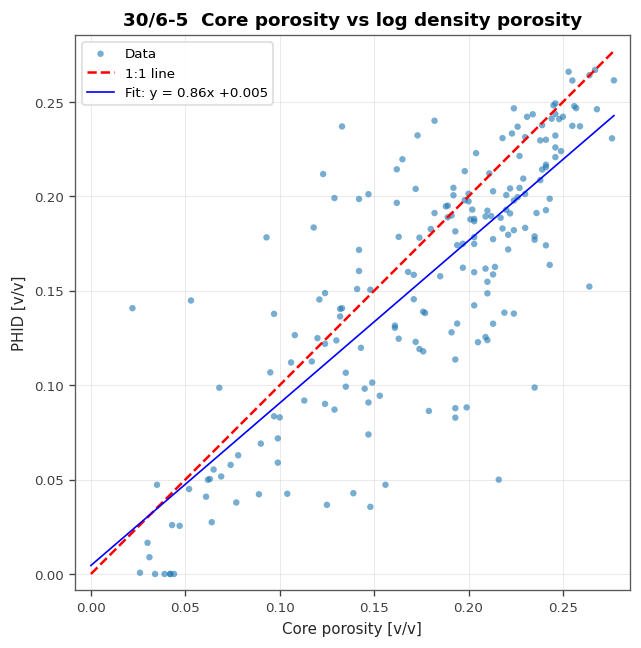

In [6]:
pp.calibration_plot(cal, title="30/6-5  Core porosity vs log density porosity");

### 1.3 A porosity correction

`fit_porosity_correction` fits $\phi_{core} = A\,\phi_{log} + B$ so we can map
the *full* log porosity onto its core-equivalent value. This is the transfer
function you would apply downstream before computing volumes. It regresses core on log, while the
calibration plot above draws log on core; with this much scatter ($R^2$ = 0.645) the two
lines differ, as least-squares fits in opposite directions always do, and the one to apply
is this one, which predicts core from log. `predict` applies
it, here to two log readings, 0.10 and 0.25:

In [7]:
from petrophys.interpretation.core_analysis import fit_porosity_correction

corr = fit_porosity_correction(logs, core, log_curve="PHID")
corr, corr.predict([0.10, 0.25])

(PorosityCorrection(PHIcore = 0.717*PHID + 0.065, R^2=0.580, RMSE=0.0383, n=193),
 array([0.13623413, 0.24372885]))

A log porosity of 0.10 corresponds to 0.136 on core and 0.25 to 0.244: the
correction lifts low porosity and leaves high porosity nearly unchanged.

### 1.4 Fitting a poro-perm transform

Permeability spans orders of magnitude, so the industry-standard transform is
linear in **log10** space:

$$\log_{10}(k) = A\,\phi + B \quad\Longleftrightarrow\quad k = 10^{B}\,10^{A\phi}$$

`fit_poro_perm` fits this straight from the `CoreData` porosity and
permeability arrays; `predict` gives the permeability at porosities 0.10, 0.20
and 0.30.

In [8]:
from petrophys.interpretation.core_analysis import fit_poro_perm

transform = fit_poro_perm(core)
transform, transform.predict([0.10, 0.20, 0.30])

(PoroPermTransform(log10(K) = 21.72*PHI + (-2.54), R²=0.777, n=198),
 array([4.32442297e-01, 6.42310286e+01, 9.54029026e+03]))

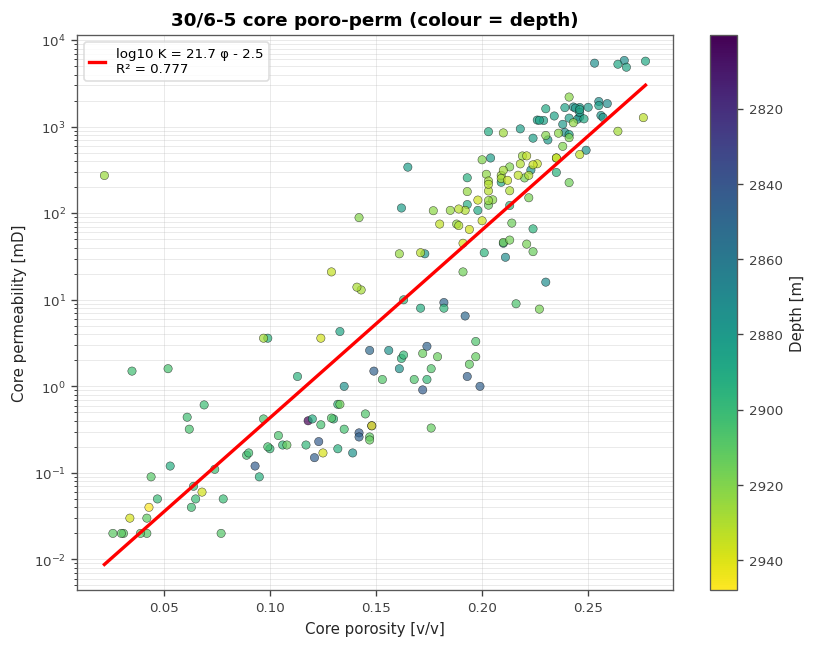

In [9]:
pp.crossplot(core, "PHIC", "KH_CORE", transform=transform, title="30/6-5 core poro-perm (colour = depth)")

On 198 plug pairs, $\log_{10}k = 21.72\,\phi - 2.54$ with $R^2$ = 0.777: about
0.4 mD at 10 % porosity, 64 mD at 20 % and 9,500 mD at 30 %.

### 1.5 Applying the transform back onto the log

`apply_poro_perm` writes a continuous predicted-permeability curve onto
the well using a chosen porosity input. We feed it our density porosity, so the
curve covers the *entire* logged interval, not just the cored plugs. It is stored
as `PERM_CC`, the name of the core-calibrated permeability the workflow writes.
The workflow is stricter than this direct call: it writes `PERM_CC` only where
clay volume is at or below the net-rock clay cutoff.

A transform is only supported where the plugs are: the cored interval (here
the Brent Group: all but one plug lie below its top at 2841 m) and the porosity
range the plugs span (0.022-0.277, `transform.porosity_min` and `porosity_max`).
Outside that, it **extrapolates**. In the shallow, poorly compacted section the
density porosity is very high, the exponential transform explodes, and the
function clips the result at its 100,000 mD ceiling. Compare the prediction over
the cored interval, over the whole well, and the plugs:

In [10]:
from petrophys.interpretation.core_analysis import apply_poro_perm

apply_poro_perm(logs, transform, porosity_curve="PHID")
pd.DataFrame({"log, cored interval": logs.depth_slice(core.top, core.bottom).to_dataframe(["PERM_CC"])["PERM_CC"].describe(),
              "log, whole well": logs.to_dataframe(["PERM_CC"])["PERM_CC"].describe(),
              "core plugs": pd.Series(core.permeability).describe()})

,"log, cored interval","log, whole well",core plugs
count,968.000,22171.000,198.000
mean,245.342,50379.864,436.942
std,1001.865,49290.008,948.796
min,0.003,0.003,0.020
25%,0.043,1.411,0.512
50%,3.006,41653.855,44.500
75%,72.203,100000.000,404.500
max,13008.111,100000.000,5826.000


Over the cored interval the log prediction has a median of 3.0 mD against
44.5 mD for the plugs. The log prediction samples **every** depth, including
the shaly beds between the sands, whereas plugs tend to be cut from the better
rock; and the density porosity reads low (the bias in section 1.2), which the
exponential transform amplifies. Feeding the transform a core-corrected porosity
(Exercise 3) is the natural next step. Over the whole well, the upper quartile
already sits at the 100,000 mD ceiling and the median is above 40,000 mD: a
whole-well statistic of this curve is meaningless.

`core_on_logs` overlays the core permeability plugs on the predicted
curve over the cored interval:

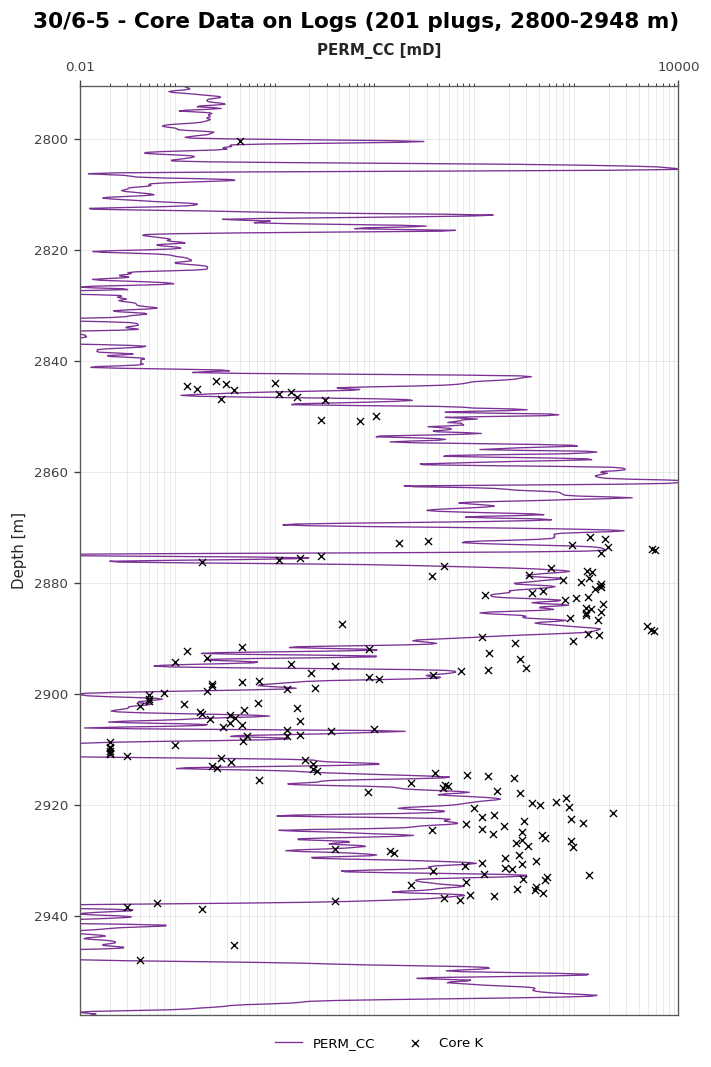

In [11]:
pp.core_on_logs(logs, core, curves=["PERM_CC"], top=core.top - 10, bottom=core.bottom + 10, figsize=(6, 9));

---
## Part 2 - Rock typing with the digital-core toolkit

Plug-based core analysis samples one point every ~30 cm. Modern **core scanning**
delivers *continuous* high-resolution logs: laser grain size, XRF elemental
chemistry, scratch-test strength, ultrasonic velocities, and RGB colour. The
digital-core readers turn these into interpretation-ready products:
`XRFData` (mineral proxies, elemental ratios; in
`petrophys.interpretation.geochemistry`) and, in
`petrophys.interpretation.core_analysis`, `GrainSizeData` (Wentworth classes, sorting, Kozeny-Carman permeability), and
`CoreMechanical` (dynamic elastic moduli from Vp/Vs).

> **Data note.** 30/6-5 carries no scanner data, so those three tools are not
> demonstrated on that well. The EpsLog collection for EDE-01
> supplies scanner inputs and matching well logs (sections 2.2-2.4). Here `DigitalCoreFacies`
> is applied to real wireline logs over the cored interval of 30/6-5 - a
> standard electrofacies workflow.

### 2.1 Facies classification with weighted K-means

`DigitalCoreFacies` standardises each input feature, applies an optional
`sqrt(weight)` emphasis, and runs K-means. The result is a `FaciesResult`
carrying the per-sample labels, cluster centroids (back in original units), and
convenience methods `proportions()` and `statistics()`.

Here we use **real 30/6-5 wireline logs** (GR, RHOB, NPHI, PEF) over the cored
interval as the multi-parameter feature set - a legitimate electrofacies
exercise - to keep the demonstration grounded in real data. `depth_slice`
cuts the cored interval out of the well, and GR gets twice the weight of the
other logs, to emphasise shaliness.

In [12]:
from petrophys.interpretation.core_analysis import DigitalCoreFacies

cored = well.depth_slice(core.top, core.bottom)
features = dict(cored.to_dataframe(["GR", "RHOB", "NPHI", "PEF"], include_depth=False).items())
facies = DigitalCoreFacies(n_facies=4, n_init=10, random_state=42).fit(cored.depth, features, weights={"GR": 2.0})

#### Per-facies statistics table

`statistics()` returns the P13 / P50 / P87 of every feature within each facies -
the fingerprint that lets you *name* the clusters (clean sand, shale,
calcite-cemented streak, etc.).

In [13]:
facies.statistics(features)

,count,proportion_pct,GR_P13,GR_P50,GR_P87,RHOB_P13,RHOB_P50,RHOB_P87,NPHI_P13,NPHI_P50,NPHI_P87,PEF_P13,PEF_P50,PEF_P87
facies,,,,,,,,,,,,,,
1,369,38.120,83.553,97.313,108.789,2.522,2.571,2.619,0.236,0.295,0.326,3.557,3.920,4.904
2,465,48.037,28.661,39.094,60.210,2.256,2.338,2.451,0.188,0.212,0.233,3.632,4.363,4.967
3,44,4.545,79.213,88.812,96.930,2.198,2.241,2.328,0.324,0.411,0.458,7.765,9.620,11.358
4,90,9.298,79.178,94.906,107.777,2.211,2.321,2.466,0.290,0.369,0.438,4.330,5.426,6.478


K-means cluster numbers are arbitrary (they can change with the library
version or random seed), so name each cluster by its fingerprint:

- **Facies 2** (48 % of the samples) has the lowest GR (median 39 API) and the
  lowest neutron (median 0.21): the clean, porous reservoir sand.
- **Facies 1** (38 %) has the highest GR (median 97 API) and the highest
  density: shale. The neutron reads high because clay-bound hydrogen counts as
  apparent porosity.
- **Facies 3 and 4** are smaller high-GR clusters pushed to **very high NPHI
  and low RHOB**, facies 3 also with a very high PEF (median 9.6 b/e): shale
  streaks with anomalous log response - bad hole or heavy minerals rather than
  a clean mineralogy signal. Clusters inherit whatever artefacts the input logs
  carry.

#### Facies on a cross-plot

A density-neutron cross-plot shows how the clusters separate in petrophysical
space. `pp.crossplot(well, "NPHI", "RHOB")` draws one with the sandstone, limestone and
dolomite matrix lines and colours the points by any curve of the well, so we add
the facies labels to the cored interval as a curve. A facies label is a
category, not a number: the legend names the four of them.

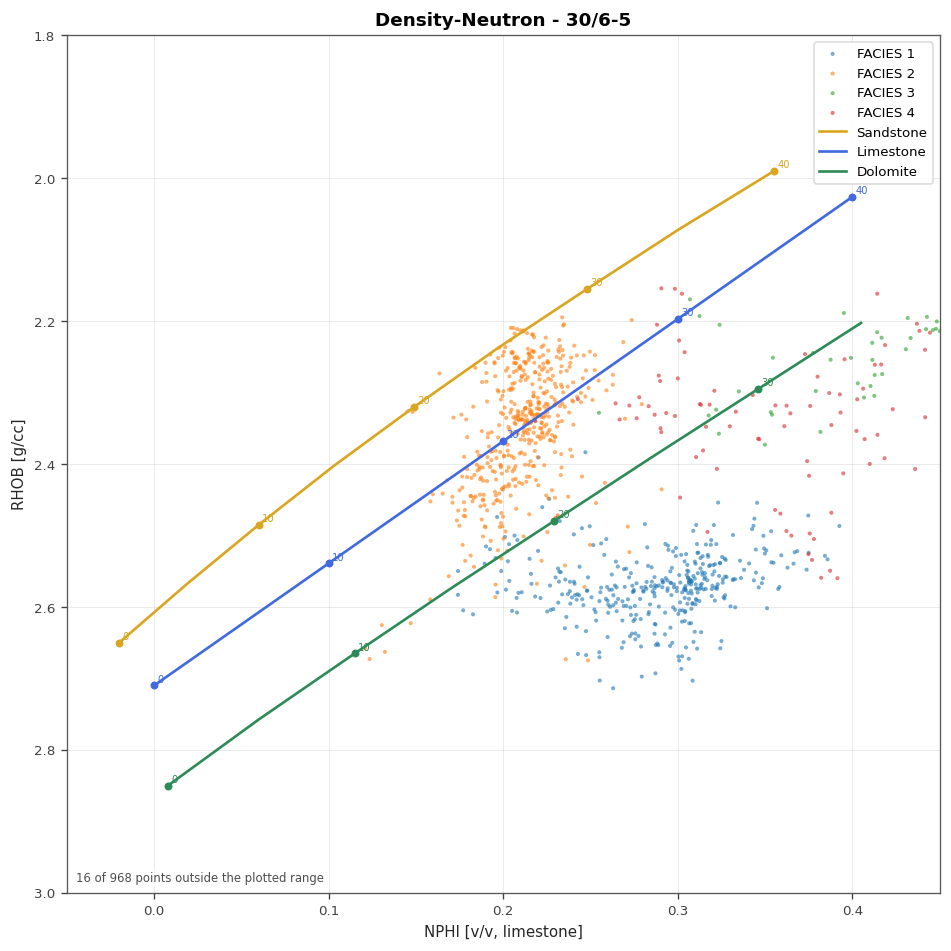

In [14]:
cored.add_curve("FACIES", facies.facies)
pp.crossplot(cored, "NPHI", "RHOB", color="FACIES")

The sand (facies 2) plots at 20-25 % porosity on and just left of the limestone line,
toward the sandstone line; the shale (facies 1) sits below the dolomite line at high neutron, the
usual shale position; facies 3 and 4 spread to the right at very high neutron.

### 2.2 EDE-01: XRF and matching well logs

Source: **NLOG.NL**, EBN / EpsLog project P005W, well EDE-01. The two
bundled LAS files retain their original contents. See the
[dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/epslog/README.md)
and [NLOG reuse terms](https://www.nlog.nl/en/disclaimer).

The scanner spans approximately 1031-1218 m and overlaps the composite well
logs. The depths below are used as delivered: overlap is not an independently
verified core-to-log depth tie. We plot missing values as gaps.

In [15]:
import lasio
from petrophys.interpretation.geochemistry import XRFData
from petrophys.interpretation.core_analysis import GrainSizeData

scanner_path = pp.sample("epslog_ede_01_scanner")
scanner_las = lasio.read(scanner_path)
scanner_well = pp.read(scanner_path)
ede = pp.read(pp.sample("ede_01_composite"))
scanner = scanner_las.df().reset_index()
scanner.rename(columns={scanner.columns[0]: "DEPTH"}, inplace=True)
scanner.notna().sum().rename("finite samples")

DEPTH                 7607
PROBE PERMEABILITY    4477
STRENGTH              6263
AL CONCENTRATION      6848
CA CONCENTRATION      6848
FE CONCENTRATION      6848
K CONCENTRATION       6848
LE CONCENTRATION      6848
MN CONCENTRATION      6848
RB CONCENTRATION      6848
S CONCENTRATION       6848
SI CONCENTRATION      6848
TI CONCENTRATION      6848
K_AL RATIO            6846
GS_P50___MERGED3      4512
BRIGHTNESS INDEX      6306
COLOR INDEX           6306
FACIES_INDEX_14       4143
DIST_CENTROID_14      4143
Name: finite samples, dtype: int64

Map concentration channels explicitly: the scanner also contains strength,
grain size and cluster labels, which must not be passed as elements. LE is
an aggregate rather than a chemical element. Rb and Ti arrive in ppm; convert
them to percent so all elemental ratios use the same mass units. XRF proxies
are relative indicators, not measured XRD mineral fractions.

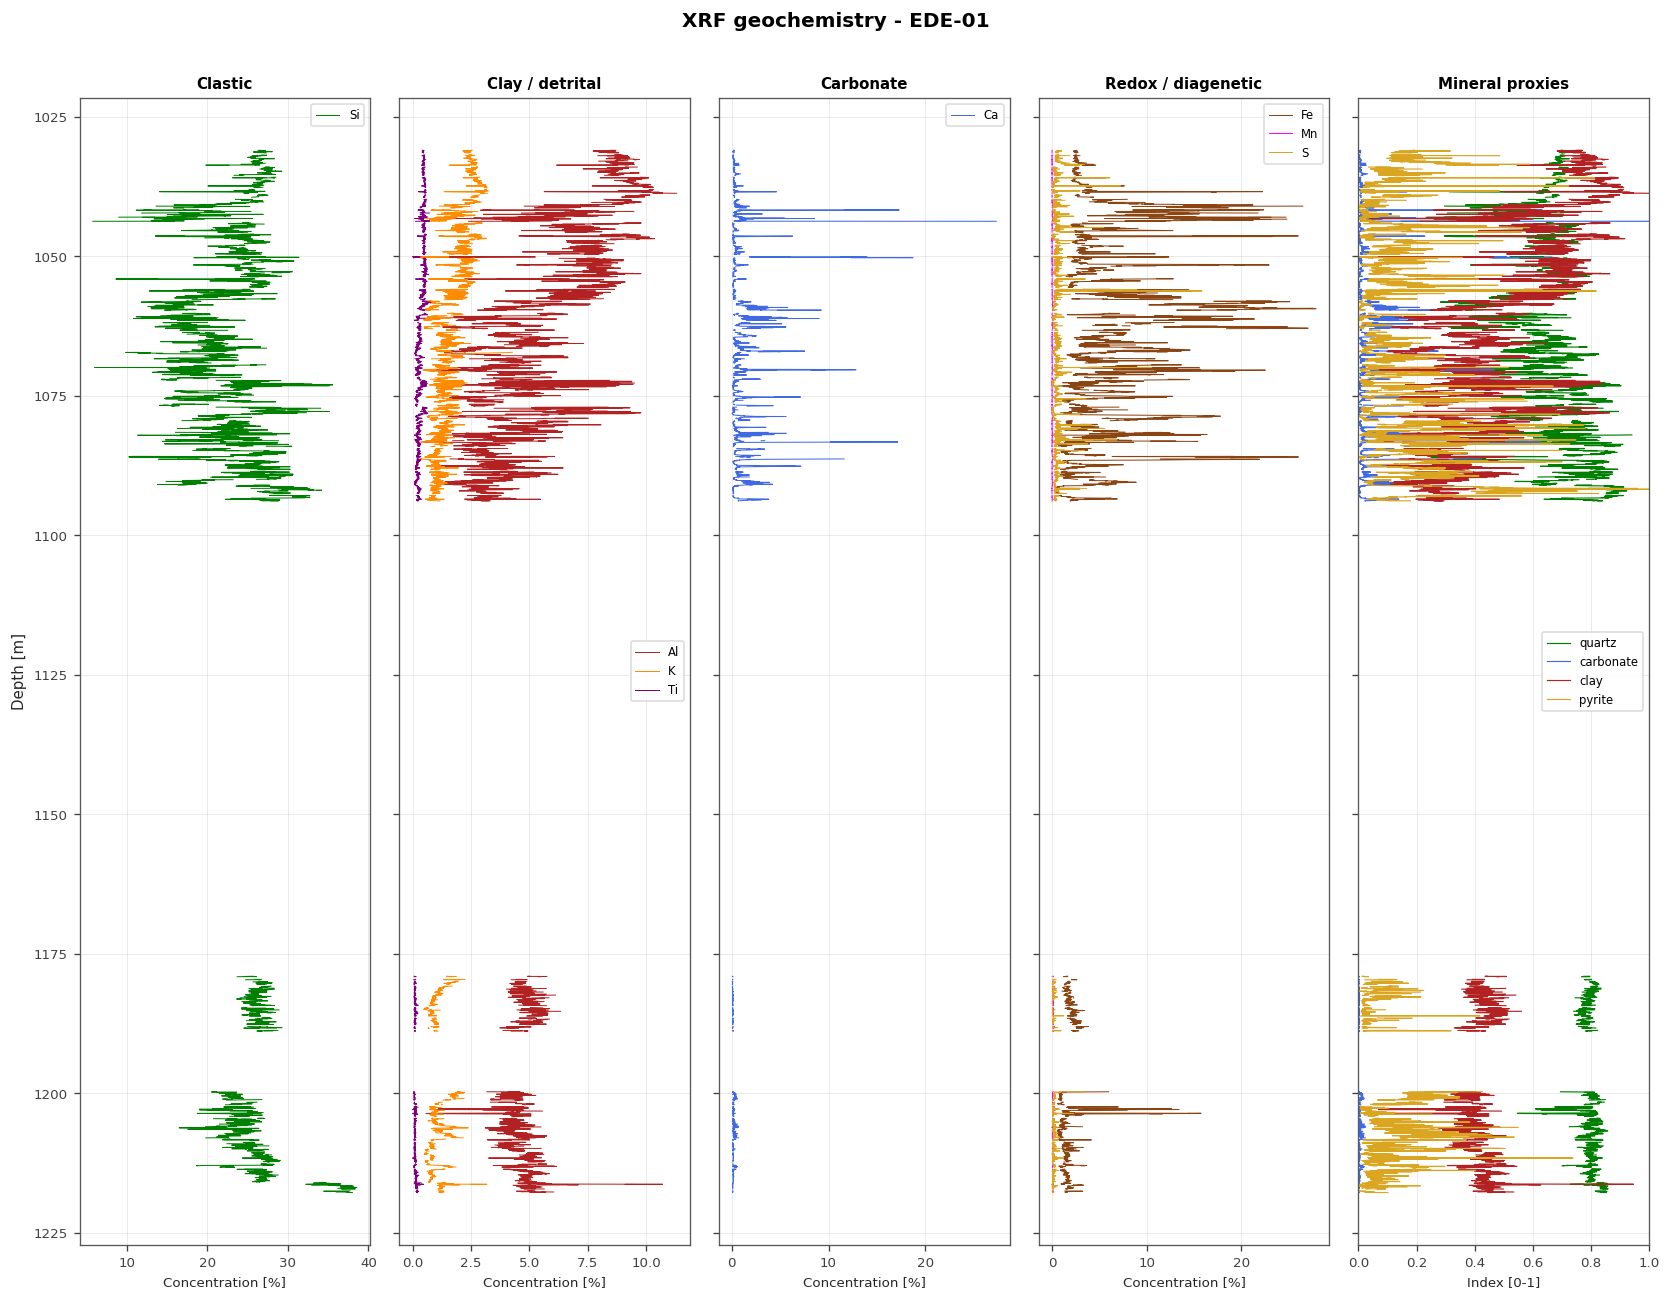

In [16]:
symbols = ["Al", "Ca", "Fe", "K", "Mn", "Rb", "S", "Si", "Ti"]
elements = {}
for symbol in symbols:
    curve = scanner_las.curves[f"{symbol.upper()} CONCENTRATION"]
    values = np.asarray(curve.data, dtype=float).copy()
    if curve.unit == "ppm":
        values /= 10000.0
    elif curve.unit != "%":
        raise ValueError(f"Unexpected XRF unit: {curve.unit}")
    elements[symbol] = values
xrf = XRFData(depth=scanner["DEPTH"].to_numpy(), elements=elements,
              units={symbol: "%" for symbol in symbols},
              metadata={"well": "EDE-01", "source": "NLOG.NL / EBN / EpsLog", "depth_unit": "m"})
ratios = xrf.elemental_ratios()
proxies = xrf.mineral_proxies()
pp.xrf_panel(xrf);

### 2.3 Grain size and measured probe permeability

The merged P50 is a delivered estimate combining laser and image-segmentation
products. Use the library's Wentworth classification, then compare grain size
with the probe permeability stored on the same scanner depth grid. Only
positive finite pairs appear on the logarithmic plot; no gap filling is used.
This compares two core-scanner products without interpolating wireline logs.

d50_um           probe_k_md         
                  count    median      count   median
class                                                
Coarse Sand          16   657.865         16    4.300
Coarse Silt         113    51.070        113    0.264
Fine Sand          2042   162.280       2042   10.675
Fine Silt            38    12.000         38    7.340
Granule               1  2470.000          1   26.940
Medium Sand        1379   305.830       1379  484.150
Medium Silt          18    21.230         18    0.327
Very Coarse Sand      8  1155.000          8    5.350
Very Fine Sand      577   101.460        577    0.667

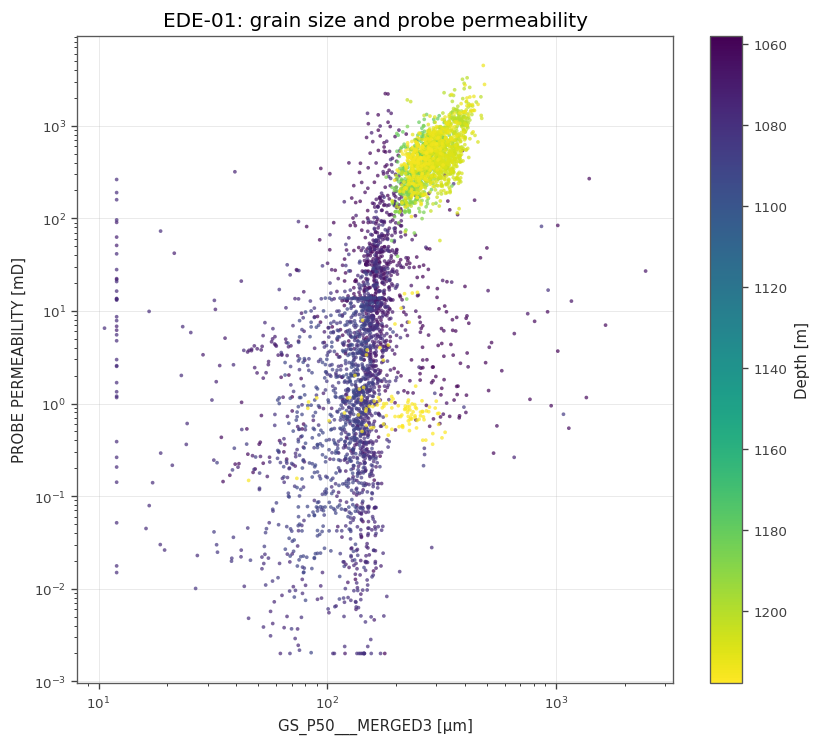

In [17]:
grain = GrainSizeData.from_las(scanner_path, d50_mnemonic="GS_P50___MERGED3",
                              d13_mnemonic=None, d87_mnemonic=None)
paired = pd.DataFrame({"depth_m": grain.depth, "d50_um": grain.d50,
                       "probe_k_md": scanner["PROBE PERMEABILITY"].to_numpy(),
                       "class": grain.wentworth()})
paired = paired.loc[np.isfinite(paired["d50_um"]) & (paired["d50_um"] > 0)
                    & np.isfinite(paired["probe_k_md"]) & (paired["probe_k_md"] > 0)]
display(paired.groupby("class")[["d50_um", "probe_k_md"]].agg(["count", "median"]))
pp.crossplot(scanner_well, "GS_P50___MERGED3", "PROBE PERMEABILITY", color="DEPTH",
             x_log=True, y_log=True, title="EDE-01: grain size and probe permeability")

Two lines in the cloud are reporting values, not rock: 16 samples sit at 0.002 mD, the
lowest probe permeability in the file, and 67 at a P50 of exactly 12.0 um. Probe
permeability is not plug Klinkenberg permeability. No laboratory core
porosity or P13/P87 is supplied here, so we do not fabricate a Kozeny-Carman
calibration or sorting coefficient. Parts 1 and 4 retain measured GeoLink
plug data for porosity/permeability calibration.

### 2.4 Scanner strength and dynamic well-log mechanics

The library computes dynamic elastic properties from RHOB (g/cm3) and sonic
slowness DTC/DTS (us/ft). It leaves unsupported results missing. This uses
the composite curves, not raw acoustic waveforms. Neutron is cased-hole
(`NPHI_CH`); sonic acquisition flags are also preserved in the composite.
The plot shows nominal depth overlap with scanner strength and is not a
static-versus-dynamic calibration. Scanner strength is not an independent
plug UCS test. Core VP/VS appear in the EpsLog report but are absent from
the bundled scanner LAS; static Young's modulus and Poisson ratio are absent.

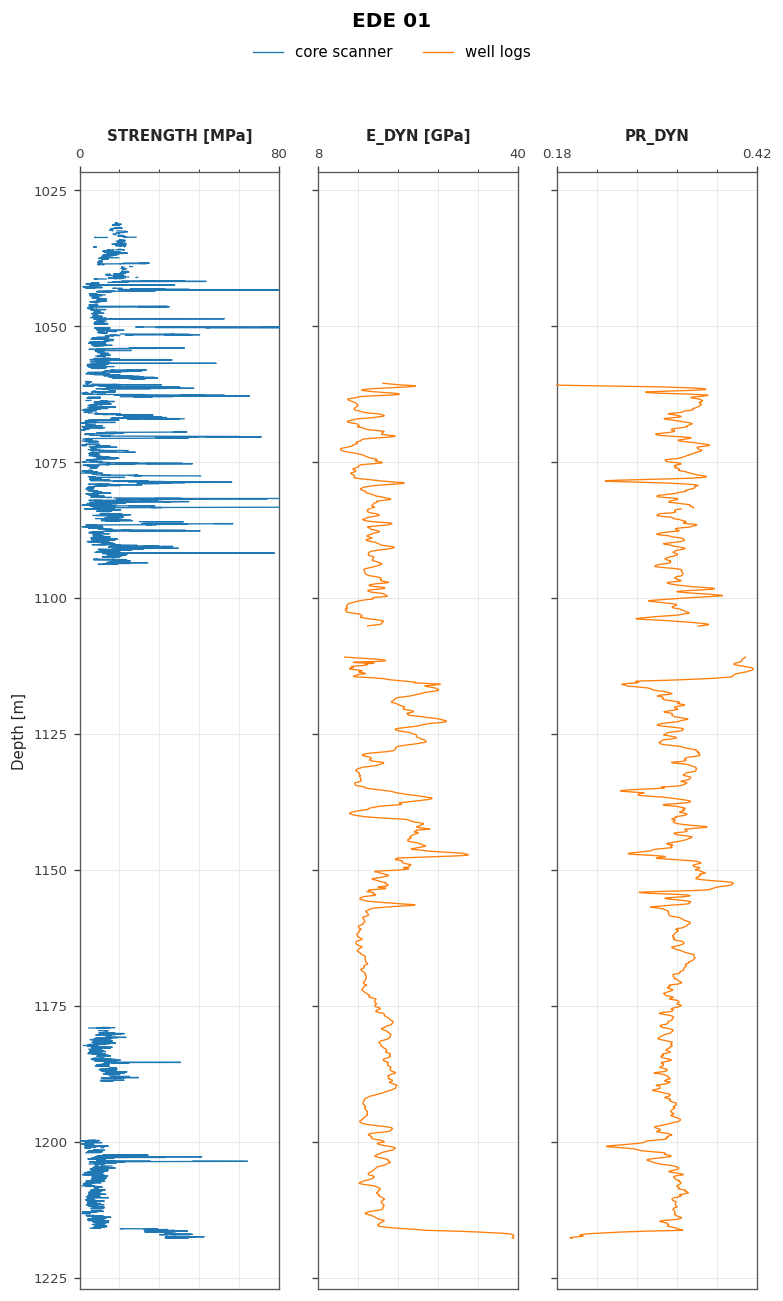

scanner strength samples    6263
valid dynamic E samples     1990
dtype: int64

In [18]:
from petrophys.interpretation.rock_physics.elastic import elastic_properties

ede_core_window = ede.depth_slice(float(grain.top), float(grain.bottom))
elastic = elastic_properties(ede_core_window.get("RHOB").data,
                             ede_core_window.get("DTC").data,
                             ede_core_window.get("DTS").data)
ede_core_window.add_curve("E_DYN", elastic.young_mod_gpa, "GPa", "Dynamic Young's modulus")
ede_core_window.add_curve("PR_DYN", elastic.poisson_ratio, "", "Dynamic Poisson's ratio")
pp.plot({"core scanner": scanner_well, "well logs": ede_core_window}, curves=["STRENGTH", "E_DYN", "PR_DYN"]).show()
pd.Series({"scanner strength samples": scanner["STRENGTH"].notna().sum(),
           "valid dynamic E samples": np.isfinite(elastic.young_mod_gpa).sum()})

---
## Part 3 - Geochemistry from spectral gamma (25/5-1)

A total gamma-ray (GR) log counts every gamma ray the formation emits. Nearly
all of them come from three natural sources: potassium-40 and the thorium and
uranium decay series. A **spectral gamma-ray** tool splits the energy spectrum
into those three elements and reports them as concentrations: potassium in %,
thorium and uranium in ppm.

The elements behave differently in sediments, which is what makes the split
useful:

- **Thorium** is insoluble. It travels with detrital clay and heavy minerals,
  so it is the most dependable radioactive clay indicator.
- **Uranium** dissolves in oxidising water and precipitates where conditions
  turn reducing, typically with organic matter. It follows redox conditions and
  organic content, not clay.
- **Potassium** sits in illite, micas and K-feldspar.

A GR-based clay volume assumes that all radioactivity comes from clay. Spectral
gamma lets you test that assumption. The bundled XRF scanner data (section 2.2)
include matching EDE-01 well logs; this part provides a second downhole
spectral geochemistry instead: the GeoLink well **25/5-1** (Frøy field, Norwegian North Sea)
carries processed thorium (`THOR`) and uranium (`URAN`) curves.

### 3.1 Inspect the spectral curves: units, coverage, plausibility

Before interpreting anything, check what the file holds: the units, the depth
interval each curve covers, and whether the values are physically plausible.

In [19]:
well25 = pp.read(pp.sample("25_5-1"))
pd.DataFrame(well25.describe()["curves"]).set_index("mnemonic").loc[["GR", "THOR", "URAN"]]

,unit,description,valid_fraction
mnemonic,,,
GR,gAPI,GR,1.000
THOR,ppm,THOR,0.185
URAN,ppm,URAN,0.185


The units are the standard ones (ppm for Th and U, API for GR). GR has a value
over almost the whole well, thorium and uranium over less than a fifth of it:
the spectral run covers only the deepest part of the well, from 2905.7 m.

Now look at the bottom of the spectral run. A real reading never repeats
exactly, to every stored decimal, for many samples in a row.
`find_held_readings` (in `petrophys.preprocessing.quality`) counts, for each
curve, the samples identical to the sample above inside a run of at least
`min_run` equal samples (10 by default, so the short repeats of quantized
curves such as a caliper in gauge hole are not flagged).

In [20]:
from petrophys.preprocessing.quality import find_held_readings

find_held_readings(well25, ["GR", "THOR", "URAN"]).summary()

,held_samples,runs,top,bottom,longest_run
curve,,,,,
GR,57,1,3423.428,3431.963,57
THOR,45,2,3424.952,3432.115,30
URAN,45,2,3424.952,3432.115,30


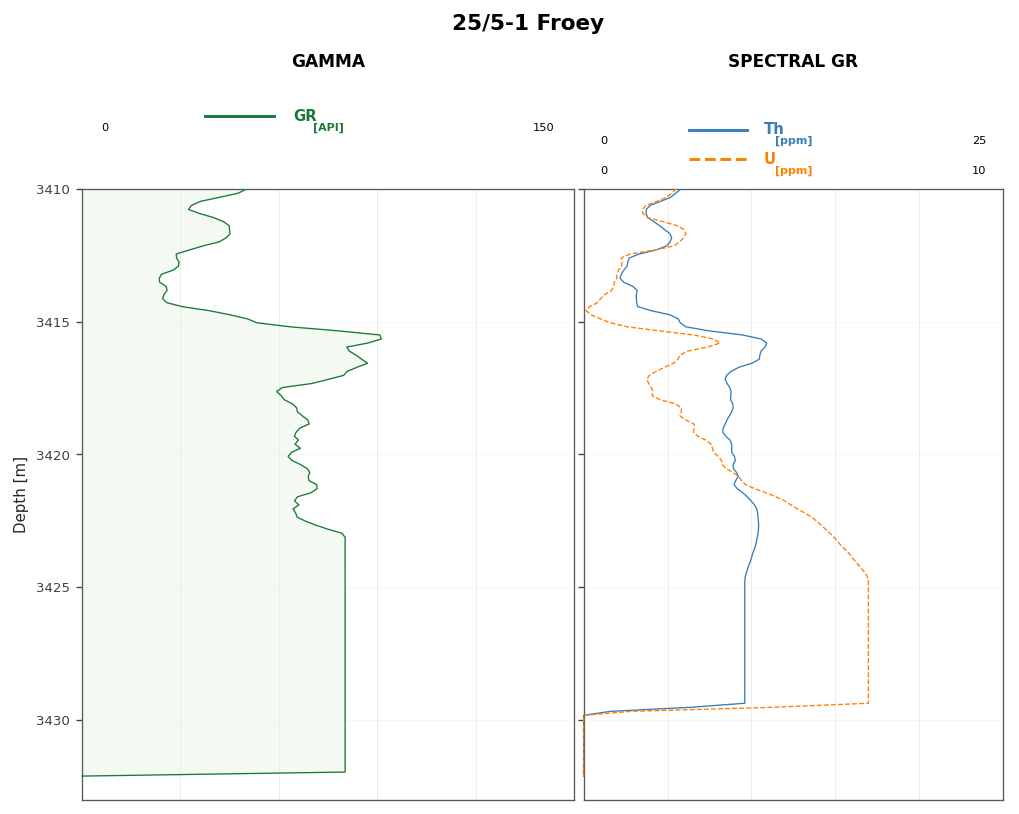

In [21]:
pp.plot(well25, curves=["GR", "THOR", "URAN"], top=3410, bottom=3433, figsize=(8, 7)).show()

Every repeat sits in the last few metres of the file. There, GR, Th and U
freeze at one value each, and then Th and U drop to exact zeros. This pattern is
typical of the bottom of a logging run: each sensor sits some distance above the
bottom of the tool string, so it never reaches the last metres of hole, and the
gap is filled with a held value or zeros. GR freezes a little higher (from
3423.4 m) than Th and U (from 3425.0 m), so it was probably recorded by a
separate sensor. These are not measurements, so the analysis window stops just
above the first repeat in any of the three curves, at 3423.3 m. Check the
bottom of every run before using a curve.

Next, plausibility. Average crustal abundances (Turekian and Wedepohl, 1961)
give a scale: an average sandstone holds about 1.7 ppm Th and 0.45 ppm U, an
average shale about 12 ppm Th and 3.7 ppm U.

In [22]:
window = well25.depth_slice(2905, 3423.3)
window.to_dataframe(["THOR", "URAN"], include_depth=False).describe(percentiles=[0.05, 0.5, 0.95])

,THOR,URAN
count,3397.000,3397.000
mean,9.735,2.993
std,4.360,5.189
min,0.755,-0.978
5%,2.235,0.141
50%,11.005,1.484
95%,15.534,13.215
max,26.014,33.630


Thorium spans the range from an average sandstone to an average shale (P5
2.2 ppm, P95 15.5 ppm), as expected in a sand-shale sequence. Median uranium
(1.5 ppm) is ordinary, but the P95 (13.2 ppm) is several times the
average-shale value: somewhere in the window there is a uranium-rich interval.

The negative uranium readings (down to -0.98 ppm) are physically impossible.
They are counting noise: the tool derives U by stripping the other elements'
contributions out of a spectrum, and at low concentrations that difference can
dip below zero. Keep them (clipping them to zero would bias averages upward),
but do not trust single-sample ratios where uranium is this small.

### 3.2 Run the spectral-gamma interpretation

`interpret_spectral_gamma` (in `petrophys.interpretation.geochemistry`) finds
processed potassium, thorium, uranium, total spectral gamma (SGR) and
uranium-free gamma (CGR) curves by mnemonic, unit and description. It converts
them to standard units (K in %, Th and U in ppm, gamma rays in API) and derives
every ratio and reconstruction its inputs allow. `pp.interpret` does not run it
(the step is listed in `result.specific_steps_skipped`), so call it directly.

A first call with `add_curves=False` changes nothing and reports what the
function finds by itself.

In [23]:
from petrophys.interpretation.geochemistry import interpret_spectral_gamma

probe = interpret_spectral_gamma(window, add_curves=False)
probe.sources, sorted(probe.derived)

({'THORIUM': 'THOR', 'URANIUM': 'URAN'}, ['SGR_URANIUM_API', 'U_TH_RATIO'])

It resolved `THOR` and `URAN`, but not a total spectral gamma ray. The mnemonic
`GR` does not say the curve came from the spectral tool, and the held readings
in 3.1 suggest a separate sensor, so the function is right not to assume it.
What the uranium share needs, though, is a total gamma ray consistent with the
Th and U curves. The plot in 3.3 shows GR rising and falling with thorium and
uranium through the window, so we tell the function to use GR as SGR with
`alias_overrides`.

That adds the uranium share of the total gamma ray, `SGR_URANIUM_FRACTION`, and
a screening flag, `SGR_URANIUM_EXCESS_FLAG`, set where uranium supplies at
least `uranium_fraction_threshold` of it (default 0.5, half of the gamma ray).
With `add_curves=True` (the default) the standardised and derived curves are
written onto the well.

In [24]:
sg = interpret_spectral_gamma(window, alias_overrides={"SGR": ["GR"]})
sg.sources, sg.conversions, sg.output_curves, sg.warnings

({'THORIUM': 'THOR', 'URANIUM': 'URAN', 'SGR': 'GR'},
 {'THORIUM': 'identity_ppm', 'URANIUM': 'identity_ppm', 'SGR': 'identity_api'},
 ['THORIUM',
  'URANIUM',
  'SGR',
  'U_TH_RATIO',
  'SGR_URANIUM_API',
  'SGR_URANIUM_FRACTION',
  'SGR_URANIUM_EXCESS_FLAG'],
 [])

- `THORIUM` and `URANIUM` are standardised copies of the inputs (the units were
  already ppm, hence `identity_ppm`).
- `U_TH_RATIO` is uranium over thorium.
- `SGR_URANIUM_API` is uranium's contribution to the gamma ray,
  8.09 API per ppm U. `SGR_URANIUM_FRACTION` divides it by the total, and
  `SGR_URANIUM_EXCESS_FLAG` marks samples where the fraction reaches the
  threshold.
- There is **no potassium**, so everything that needs it is absent:
  `TH_K_RATIO`, `U_K_RATIO`, and the reconstructed gamma rays `CGR_CALC` and
  `SGR_CALC`. Section 3.6 explains what they would have added.

### 3.3 Th/U ratio and depositional environment

Thorium stays with detrital minerals while uranium moves with redox conditions,
so their ratio records the chemistry of the depositional environment. The
standard thresholds come from Adams and Weaver (1958) and were popularised for
well logs by Fertl (1979):

| Th/U | Library class | Typical setting |
|---|---|---|
| > 7 | `continental oxidising` | uranium leached out (weathered, terrestrial sediments) |
| 2 - 7 | `marine` | grey and green shales, greywackes |
| < 2 | `marine reducing` | black, organic-rich shales that fix uranium |

`classify_th_u_environment` (in `petrophys.interpretation.geochemistry`)
applies these thresholds (`TH_U_ENVIRONMENT_THRESHOLDS`). It computes Th/U
only where uranium is at least `uranium_floor_ppm`, 0.5 ppm here: near zero, a
single uranium sample is mostly noise and its ratio means nothing. (The
spectral-gamma result reports the reciprocal, `U_TH_RATIO`, which stays finite
as uranium approaches zero.) `summary` splits the window with the library's
uranium flag.

In [25]:
from petrophys.interpretation.geochemistry import classify_th_u_environment

env = classify_th_u_environment(window.get("THORIUM"), window.get("URANIUM"), uranium_floor_ppm=0.5)
uranium_rich = sg.derived["SGR_URANIUM_EXCESS_FLAG"] == 1
env, env.summary({"uranium-dominated": uranium_rich, "rest of window": ~uranium_rich})

(ThUEnvironment(2944 of 3401 samples rated (U >= 0.5 ppm), median Th/U 5.8: marine reducing 16%, marine 45%, continental oxidising 39%),
                    samples  median Th/U  marine reducing (%)  marine (%)  \
 uranium-dominated      373        0.793               95.442       4.290   
 rest of window        2571        6.475                4.434      51.147   
 
                    continental oxidising (%)  
 uranium-dominated                      0.268  
 rest of window                        44.419  )

Of the 3401 samples in the window, 2944 carry enough uranium to be rated; their
median Th/U is 5.8. The depth plot shows where the uranium-dominated samples
fall, beside the lithology labels in the file (`LITHOLOGY_GEOLINK`), an
independent description of the rock. GR runs above 150 API in the
uranium-rich beds, and uranium reaches about 34 ppm, so `curve_styles` widens both scales.

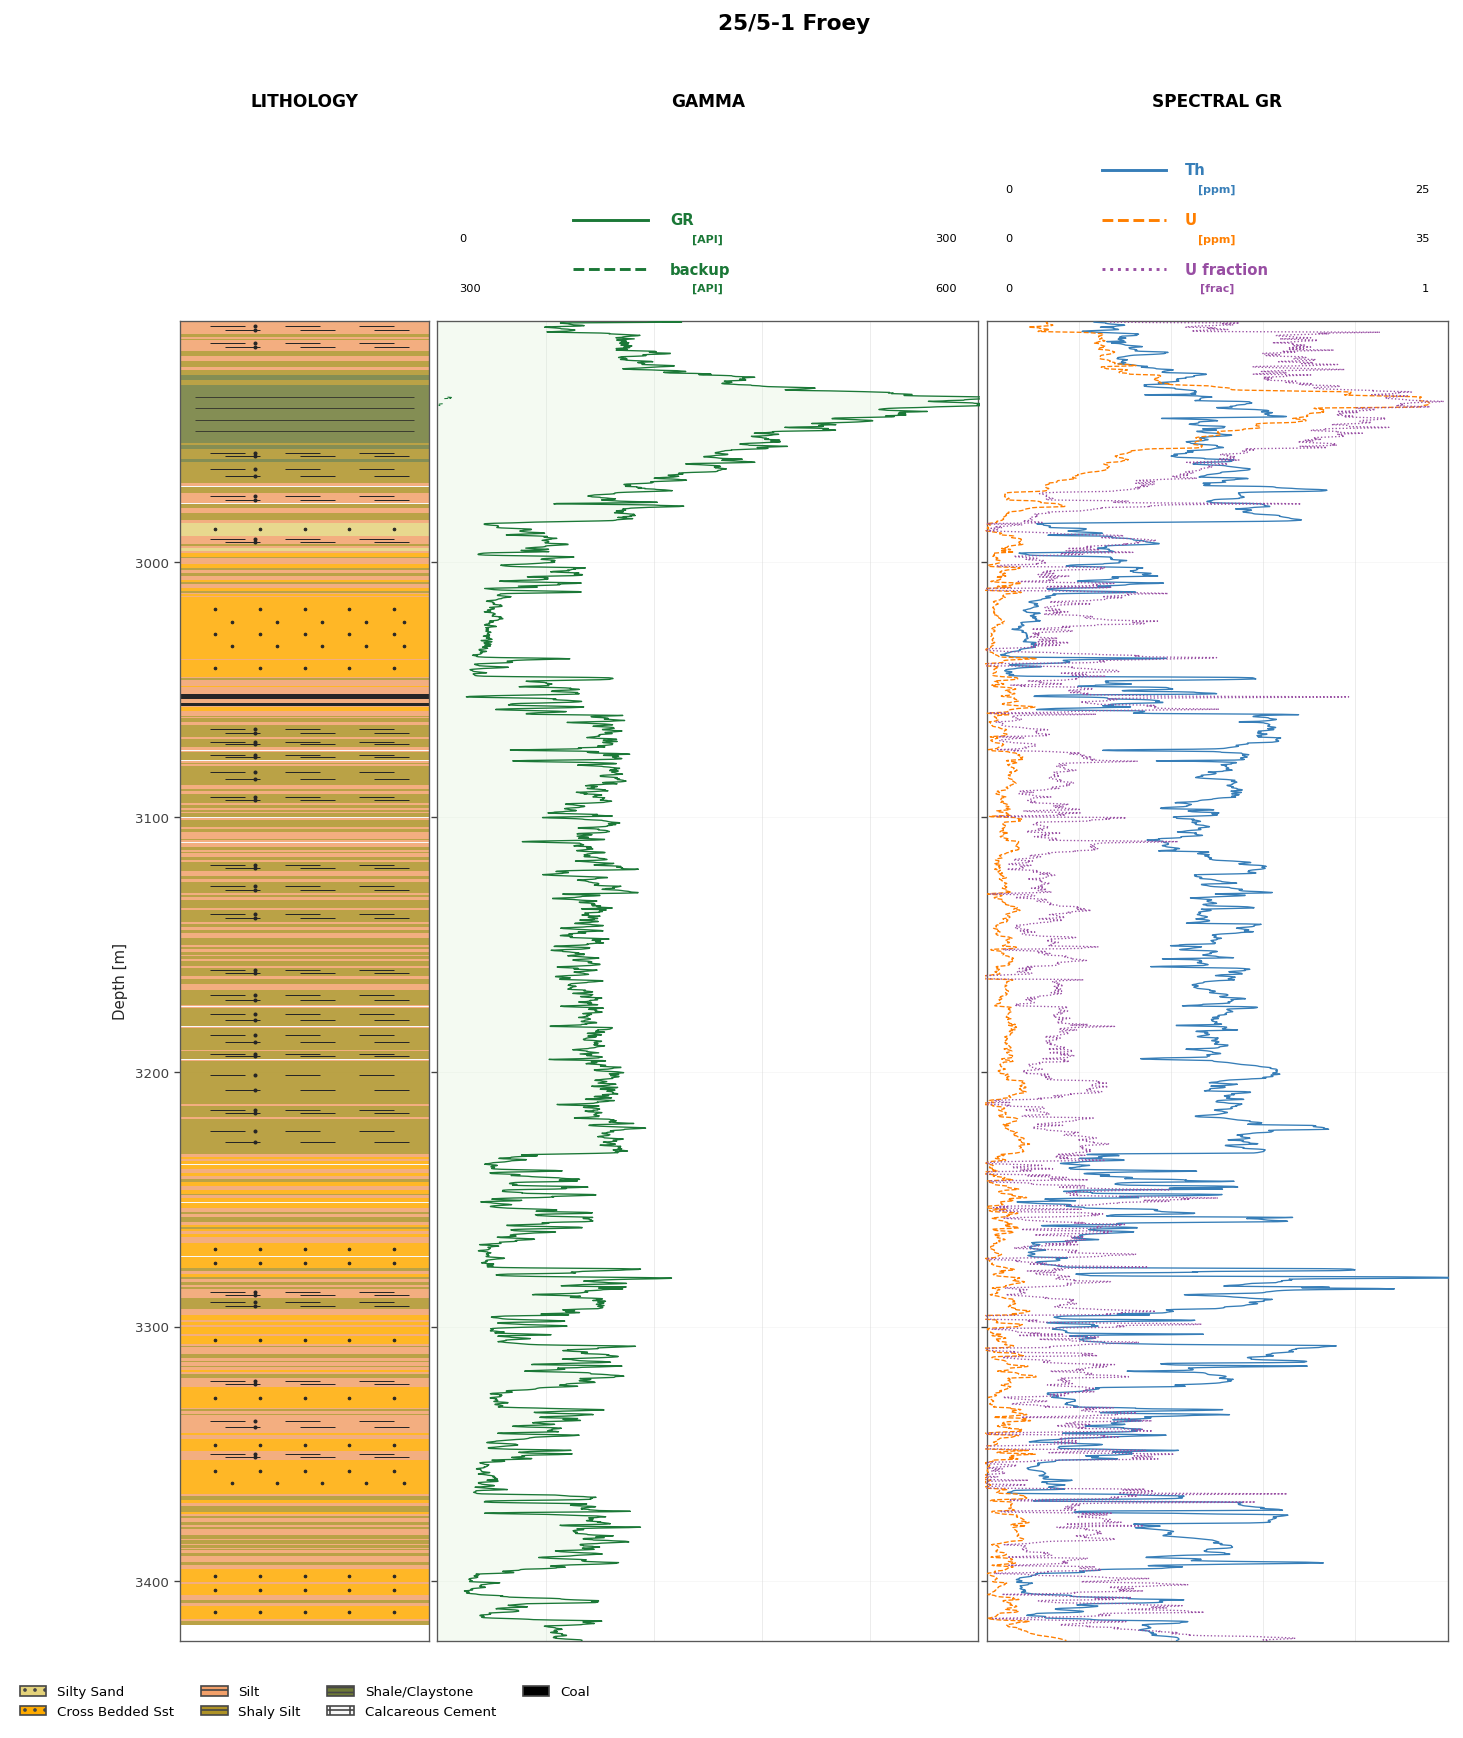

In [26]:
pp.plot(window, curves=["LITHOLOGY_GEOLINK", "GR", "THORIUM", "URANIUM", "SGR_URANIUM_FRACTION"],
        curve_styles={"GR": {"right": 300}, "URANIUM": {"left": 0, "right": 35}}).show()

Reading the table and the plot together:

- **The uranium-dominated interval** is concentrated at the top of the window
  (about 2908-2960 m), where GR reaches its highest values and uranium supplies
  most of it. There, 95 % of the rated samples have Th/U below 2 (median 0.8),
  the signature of a **marine, reducing, organic-rich shale**. The lithology
  track agrees: shale and shaly silt. In the northern North Sea, the Upper
  Jurassic Draupne Formation, which caps the Middle Jurassic reservoirs together
  with the underlying, less radioactive Heather Formation, is the classic
  uranium-rich "hot shale". The file carries no formation tops, though, so
  treat that name as a hypothesis to check against a tops list.
- **The rest of the window** straddles the marine/continental boundary: its
  median Th/U (6.5) sits just below 7, with 51 % marine and 44 % continental.
  That fits a mixed shallow-marine to continental setting such as a delta. The
  coal among the lithology labels, which forms on land, supports it.
- **Thin uranium spikes** deeper in the window are single beds. Uranium also
  concentrates in fractures, phosphatic beds and at unconformities, so read
  thin spikes individually rather than as an environment.

Th/U is a screening indicator. Read it over intervals rather than sample by
sample, and confirm it with other evidence (tops, lithology, cuttings, core).

### 3.4 A thorium clay indicator versus the GR clay volume

The simplest clay indicator from any radioactive curve is the linear index

$$I_x = \frac{x - x_{clean}}{x_{shale} - x_{clean}}, \quad \text{clipped to } 0-1.$$

For GR it is the familiar **IGR**, the linear GR clay volume (the upper bound of
the non-linear Larionov, Stieber and Clavier corrections). Applied to thorium,
it gives **ITh**, a clay indicator that uranium cannot disturb.

To compare like with like, both indices use the same baseline rule over the
same window: clean = P5 and shale = P95. `thorium_clay_index` (in
`petrophys.interpretation.geochemistry`) picks those baselines itself;
`vcl_from_gr` (in `petrophys.interpretation.clay_volume`) takes the GR
baselines as given, so we pass it the P5 and P95 of GR. We add both indices to
the well as curves.

In [27]:
from petrophys.interpretation.clay_volume import vcl_from_gr
from petrophys.interpretation.geochemistry import thorium_clay_index

ith = thorium_clay_index(window.get("THORIUM"))
window.add_curve("ITH", ith.index, "v/v")
window.add_curve("IGR", vcl_from_gr(window.get("GR"), *np.nanpercentile(window.get("GR").data, [5, 95])), "v/v")
ith

ThoriumClayIndex(clean 2.23 ppm, shale 15.53 ppm, median index 0.66)

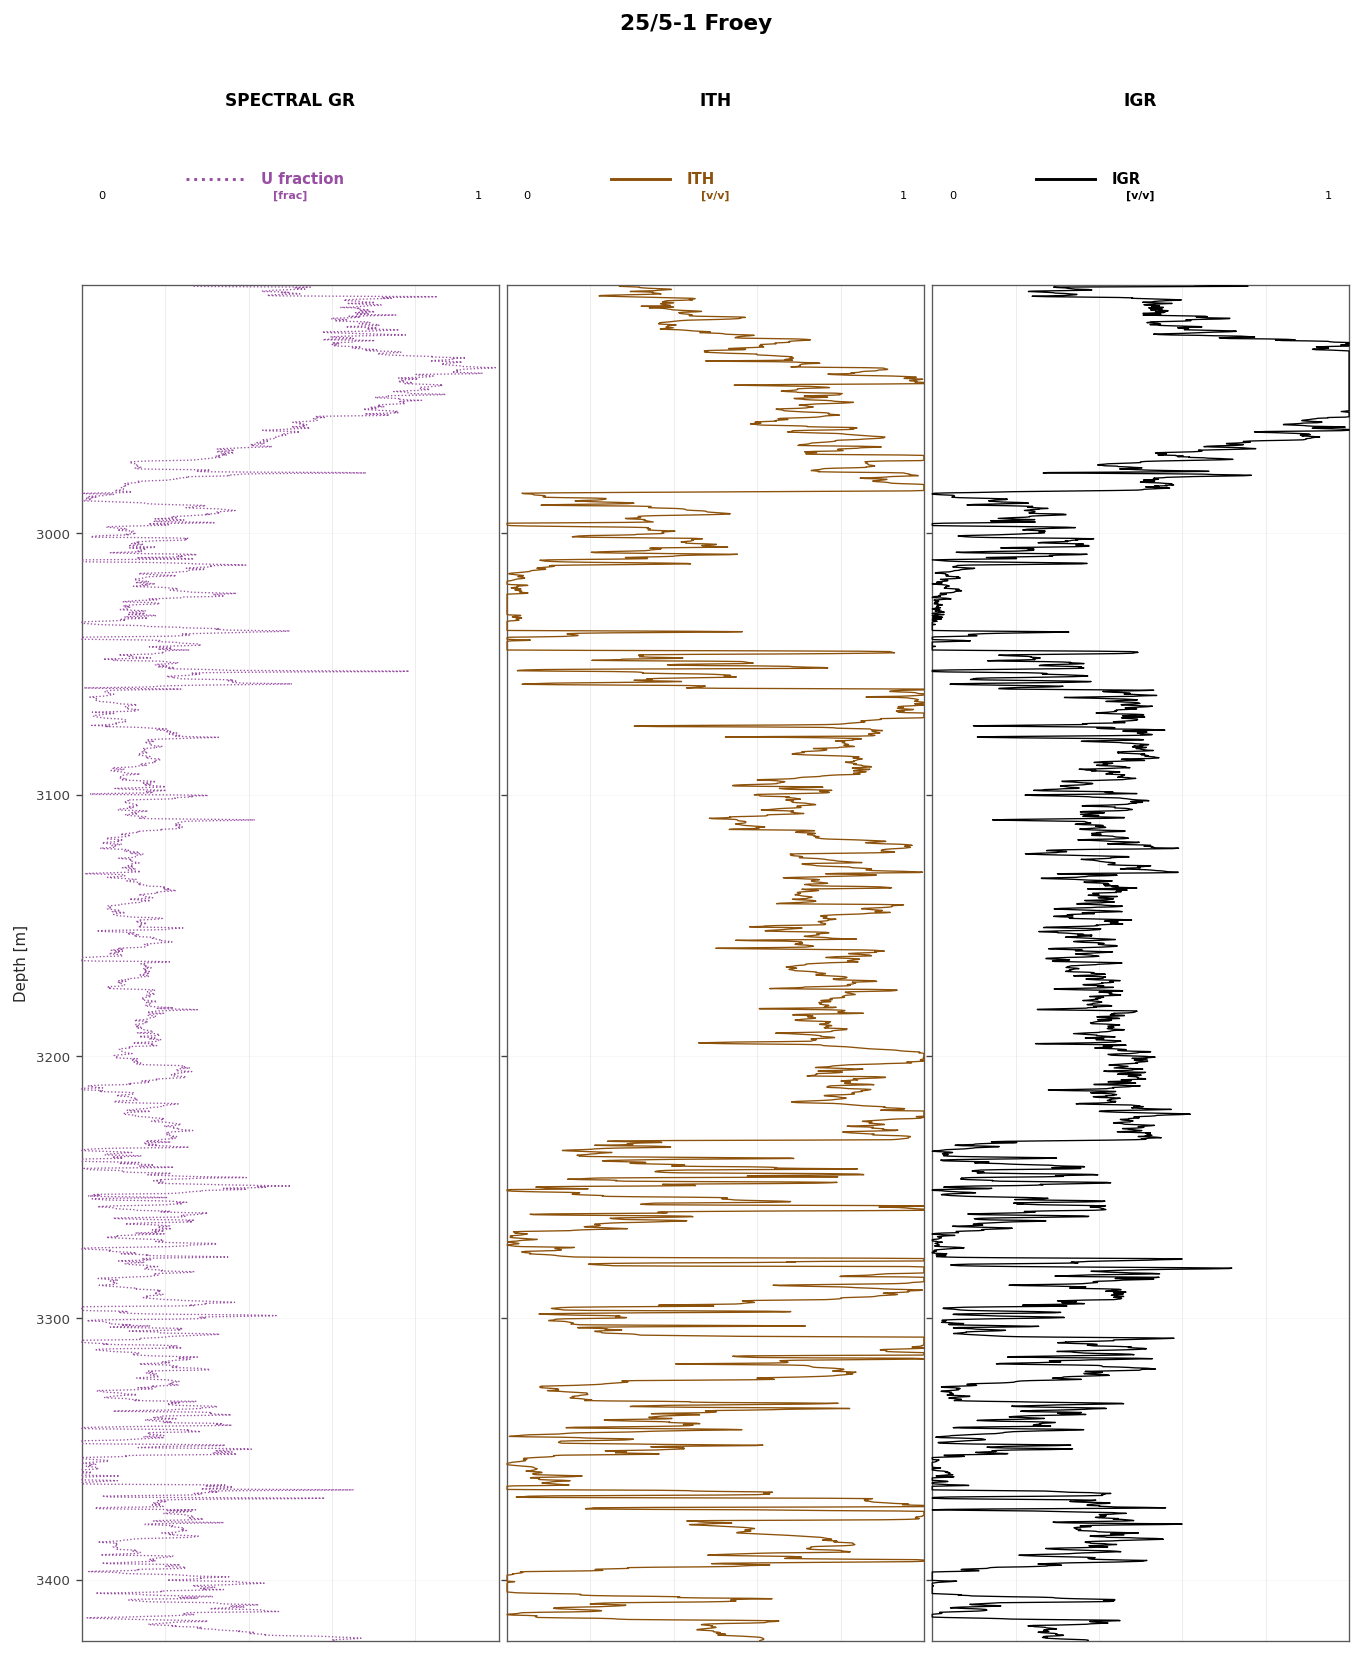

In [28]:
pp.plot(window, curves=["SGR_URANIUM_FRACTION", "IGR", "ITH"]).show()

### 3.5 Where uranium decouples GR from clay

The medians of the two indices in each part of the window put numbers on what
the plot shows:

In [29]:
indices = window.to_dataframe(["IGR", "ITH"], include_depth=False)
indices.groupby(np.where(uranium_rich, "uranium-dominated", "rest of window")).median()

,IGR,ITH
rest of window,0.349,0.666
uranium-dominated,0.949,0.643


Uranium corrupts the GR clay volume in two ways:

1. **Locally, it over-reads.** In the uranium-dominated beds, GR is high because
   of uranium, not clay, so IGR (median 0.95) sits far above ITh (0.64) and
   mostly saturates at 1.
2. **Globally, it under-reads, through the baseline.** The shale baseline
   (P95 of GR) is set by those uranium-rich beds. Every ordinary shale then looks
   only partly shaly, and IGR (median 0.35) sits far below ITh (0.67) across the
   rest of the window, even though the two curves rise and fall together there.

The fix is to take uranium out of GR before picking baselines. Without potassium
there is no tool-computed uranium-free gamma ray (CGR), but GR minus uranium's
contribution (8.09 API per ppm U) approximates it. `uranium_stripped_gamma_ray`
(in `petrophys.interpretation.geochemistry`) computes that difference; it is
the same as GR minus the spectral result's `SGR_URANIUM_API`.

In [30]:
from petrophys.interpretation.geochemistry import uranium_stripped_gamma_ray

gr_no_u = uranium_stripped_gamma_ray(window.get("GR"), window.get("URANIUM"))
indices["IGR_NO_U"] = vcl_from_gr(gr_no_u, *np.nanpercentile(gr_no_u, [5, 95]))
indices.groupby(np.where(uranium_rich, "uranium-dominated", "rest of window")).median()

,IGR,ITH,IGR_NO_U
rest of window,0.349,0.666,0.634
uranium-dominated,0.949,0.643,0.311


With uranium removed, the shale baseline drops to a normal shale value. Outside
the uranium-dominated beds, the stripped index agrees with ITh (median
0.63 against 0.67). Inside them, the correction overshoots (0.31 against 0.64).
There, uranium supplies most of the gamma ray, so the correction is larger than
what remains, and a small error in the nominal 8.09 API/ppm sensitivity
dominates the result. In uranium-rich beds, ITh is the more robust clay
indicator.

**Why this matters.** GR clay volume feeds effective porosity, shaly-sand
saturation and the net-reservoir cutoff. The local error writes off
uranium-rich rock as shale. That rock is not always a shale: uranium also
precipitates from formation water in permeable beds, so a uranium-bearing
sand can be a missed pay zone. The baseline error is less visible and hurts
more, because it biases the clay volume of every sample in the interval. When
spectral gamma is available, pick GR baselines on a uranium-free gamma ray, or
cross-check GR clay volume against thorium.

### 3.6 What potassium would have added

25/5-1 has no potassium curve (`POTASSIUM` is missing from `sg.sources`), so
the library skipped every product that needs one. With potassium the analysis
would gain:

- **A true uranium-free gamma ray.** `CGR_CALC` = 16.32 K + 3.93 Th (API), or a
  tool CGR curve. It needs neither the nominal-sensitivity stripping used above
  nor the assumption that GR and the spectral curves share a calibration.
- **The K-Th crossplot for clay typing.** Thorium plotted against potassium
  separates clay families by their Th/K ratio (`TH_K_RATIO`), following Quirein
  et al. (1982) and the service-company charts built on it. Kaolinite is
  thorium-bearing and almost potassium-free (high Th/K). Illite and micas carry
  potassium (lower Th/K). K-feldspar sits at the potassium end. Clay type
  matters downstream: it sets the cation-exchange capacity used by shaly-sand
  saturation models and the clay end-points of the density-neutron crossplot.
- **Radioactive sands.** K-feldspar and mica in an arkosic sand raise GR with
  no clay present. Only a potassium curve reveals it, and ITh cannot see it
  either.

**References for Part 3**

- Adams, J.A.S. and Weaver, C.E. (1958). Thorium-to-uranium ratios as
  indicators of sedimentary processes: example of concept of geochemical
  facies. *AAPG Bulletin* 42(2), 387-430.
- Fertl, W.H. (1979). Gamma ray spectral data assists in complex formation
  evaluation. *The Log Analyst* 20(5).
- Quirein, J.A., Gardner, J.S. and Watson, J.T. (1982). Combined natural gamma
  ray spectral / litho-density measurements applied to complex lithologies.
  SPE 11143.
- Turekian, K.K. and Wedepohl, K.H. (1961). Distribution of the elements in
  some major units of the Earth's crust. *GSA Bulletin* 72(2), 175-192.

---
## Part 4 - Calibrate against a second well's core (25/5-1)

25/5-1 also carries core plugs merged into its LAS file: `PHIC`, `KH_CORE`,
`GDEN` and `SWC`/`SOC`. Repeating the Part 1 recipe on it answers a practical
question: can a transform fitted in one well be used in another?

### 4.1 The same calibration, a second well

Same density-porosity settings (`rho_ma=2.65`, `rho_fl=1.0`), same calibration
call.

In [31]:
core25 = core_data(well25)
logs25 = pp.interpret(well25, rho_ma=2.65, rho_fl=1.0).well
cal25 = calibrate_porosity(logs25, core25, log_curve="PHID")
core25, cal25

(CoreData(plugs=333, depth=2990.3-3286.3, props=[porosity, perm, GD, Sw]),
 CalibrationResult(Porosity (PHID): n=331, R^2=0.092, bias=-0.0014, RMSE=0.0911, log = 0.407*core + 0.0931))

On 25/5-1 (333 plugs, 2990.3-3286.3 m) the tie between core and log porosity
almost disappears: $R^2$ = 0.092 against 0.645 on 30/6-5. Before blaming the
rock, check the **depth tie**. Plug depths come from the driller's pipe
measurement when the core was cut, while logs are depth-measured on the
wireline cable. Offsets of a metre or more between the two are common, and each
core run can have its own. This file carries no core gamma to match against the
log GR, so we scan whole-sample shifts of the core depths with
`find_core_depth_shift` (in `petrophys.interpretation.core_analysis`). At each
shift it measures how well core porosity tracks density porosity (the Pearson
correlation), by default over +/- 30 log samples. With `run_gap` it also scans
each core run on its own (runs separated by gaps over 1.5 m, at least 30
plugs), and `shift_core_depths` applies the chosen shift.

A shift picked this way is fitted to the same data it is judged on, so the
post-shift statistics are optimistic. The consistency check is the core runs:
a genuine depth error gives each run a shift of similar size.

In [32]:
from petrophys.interpretation.core_analysis import find_core_depth_shift, shift_core_depths

scan25 = find_core_depth_shift(logs25, core25, log_curve="PHID", run_gap=1.5, min_run_plugs=30)
scan25, scan25.runs

(CoreDepthShift(porosity vs PHID: shift +2.89 m, r = 0.661 (unshifted 0.303), n = 331, searched -4.57 to +4.57 m),
         top    bottom  plugs  shift  correlation
 0  2990.308  3041.819    173  3.047        0.614
 1  3235.214  3252.435     58  2.742        0.533
 2  3257.312  3275.295     66  1.981        0.903)

In [33]:
core25_tied = shift_core_depths(core25, scan25)
cal25_tied = calibrate_porosity(logs25, core25_tied, log_curve="PHID")
cal25_tied

CalibrationResult(Porosity (PHID): n=331, R^2=0.436, bias=-0.0037, RMSE=0.0618, log = 0.827*core + 0.0238)

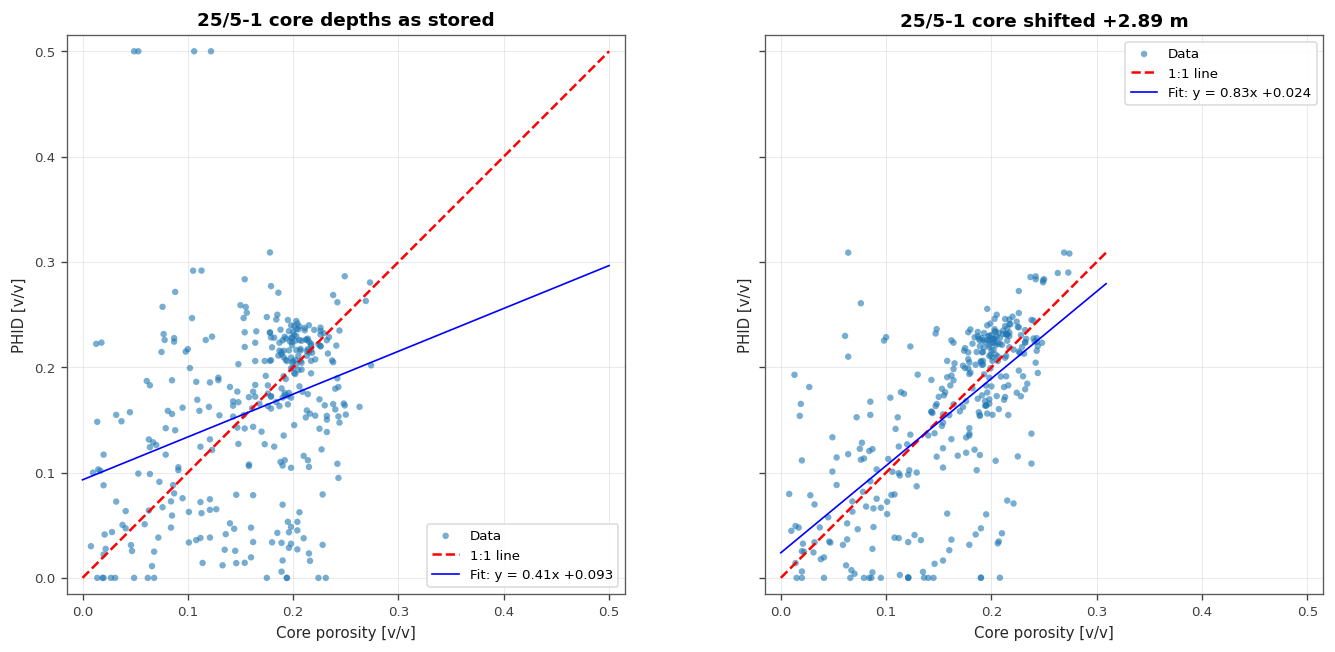

In [34]:
pp.calibration_plot({"25/5-1 core depths as stored": cal25, "25/5-1 core shifted +2.89 m": cal25_tied});

The best bulk shift is +2.89 m (log depth = core depth + 2.89 m): the
correlation rises from 0.30 to 0.66, and $R^2$ from 0.092 to 0.436. The three
core runs each prefer a shift of the same sign and similar size (+3.05, +2.74
and +1.98 m), which points to a real depth offset rather than a chance
correlation peak. A production depth match would shift each run on its own,
ideally by matching core gamma to log GR. Here the bulk shift is enough to
compare the wells. The points on PHID 0 and 0.5 are clipped readings: density porosity is
limited to 0-0.5, so tight and bad-hole samples pile up on those edges.

The **poro-perm transform** needs no depth tie at all: plug porosity and plug
permeability come from the same plug, so shifting depths cannot change it.

### 4.2 Compare the transforms

In [35]:
transform25 = fit_poro_perm(core25)
corr25 = fit_porosity_correction(logs25, core25_tied, log_curve="PHID")
transform25, corr25

(PoroPermTransform(log10(K) = 22.28*PHI + (-2.44), R²=0.841, n=316),
 PorosityCorrection(PHIcore = 0.574*PHID + 0.068, R^2=0.431, RMSE=0.0470, n=306))

In [36]:
porosity = [0.10, 0.20, 0.25]
pd.DataFrame({"30/6-5 k (mD)": transform.predict(porosity), "25/5-1 k (mD)": transform25.predict(porosity)},
             index=pd.Index(porosity, name="porosity"))

,30/6-5 k (mD),25/5-1 k (mD)
porosity,,
0.10,0.432,0.615
0.20,64.231,104.083
0.25,782.804,1353.623


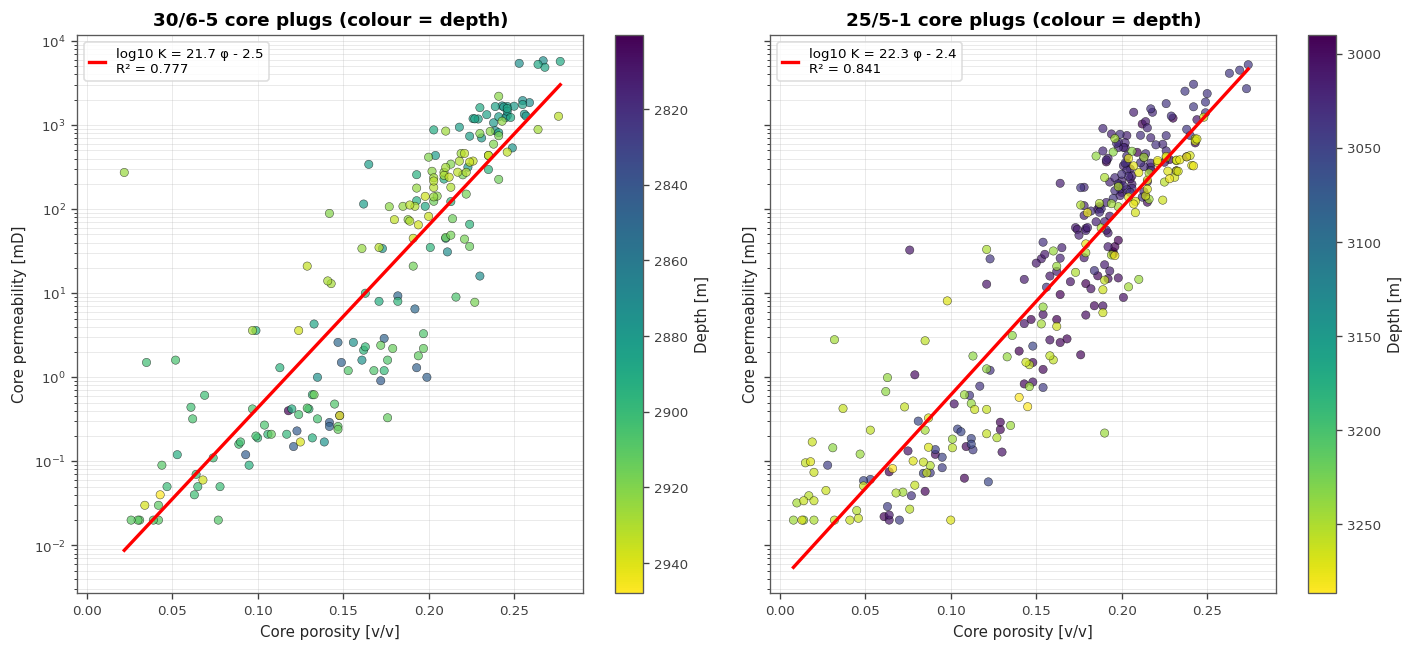

In [37]:
pp.crossplot({"30/6-5 core plugs (colour = depth)": (core, transform),
             "25/5-1 core plugs (colour = depth)": (core25, transform25)}, "PHIC", "KH_CORE")

Read the comparison in two halves.

- **The rock side (poro-perm).** Here the two transforms are close:
  $\log_{10}k = 22.28\,\phi - 2.44$ on 25/5-1 against $21.72\,\phi - 2.54$ on
  30/6-5. At the same porosity the 25/5-1 line gives 1.4 to 1.7 times the
  permeability of the 30/6-5 line (table above), so carried to 25/5-1 the
  30/6-5 transform under-predicts by about that factor. That is small beside
  the scatter of the plugs around either line, which spans more than a decade
  at any porosity. This is a **finding, not a given**: you know it only because
  25/5-1 has core of its own.
- **The log side (porosity correction).** The log-to-core porosity corrections
  differ (0.717 PHID + 0.065 on 30/6-5, 0.574 PHID + 0.068 on 25/5-1), and on
  25/5-1 no meaningful correction could be fitted until the depth tie was fixed.

Why transforms do not carry across wells without checking:

- **Porosity is only one control on permeability.** Grain size and sorting,
  the amount and habit of clay (pore-lining illite versus discrete kaolinite),
  and cementation all move the poro-perm line. They vary with depositional
  facies and with burial and temperature history, so they can differ between
  wells in the same field.
- **The log side belongs to one well.** A density-porosity correction absorbs
  that well's grain density, borehole conditions, mud and depth tie, none of
  which transfer.
- **Sampling differs.** Plugs are cut where the core allowed, and a transform
  is supported only over the porosity range of its own plugs (Part 1.5).
  Another well's rock may fall outside that range.

In practice, carry a transform to a new well only after testing it against that
well's core or well-test permeability. With no such data, carry the spread
between candidate transforms as uncertainty rather than a single line.

## Pitfalls and parameter choices

- **Calibrate against an *independent* log.** Comparing a curve against itself
  gives a meaningless $R^2 = 1$. We calibrated the density porosity `PHID`,
  computed from RHOB alone, so the comparison against core `PHIC` is real.
- **Depth-matching.** Core depth and log depth are rarely on the same datum.
  `calibrate_porosity` interpolates the log at the core depths *as stored*, so
  an offset silently destroys the correlation - on 25/5-1 it hid almost the
  whole tie until the core was shifted. Scan shifts (`find_core_depth_shift`)
  before trusting a poor calibration, and shift each core run on its own in
  production work.
- **Poro-perm is log-linear.** Never fit permeability in linear space; a few
  high-perm plugs will dominate the least-squares fit. `fit_poro_perm`
  works in $\log_{10}$ for exactly this reason.
- **A transform is valid where the core is.** Applied outside the cored rock
  types and porosity range it extrapolates, often to the clip limits. Report
  predicted permeability for the calibrated interval, not the whole well, and
  test a transform against a new well's core before reusing it there.
- **K-means needs scaling and sensible K.** `DigitalCoreFacies` standardises
  features for you, but *you* choose `n_facies` and the weights. Too many facies
  over-fits noise; too few merges distinct rock types.
- **Check the bottom of every logging run.** Sensors above the tool bottom
  cannot reach the last metres of hole; files often fill that gap with a held
  value or zeros. Exact repeats are the tell-tale sign (`find_held_readings`).
- **Uranium is not clay.** A GR clay volume over-reads in uranium-rich beds,
  and a shale baseline picked in them makes every other shale look too clean.
  With spectral gamma, pick baselines on a uranium-free gamma ray or cross-check
  against thorium.
- **Read Th/U over intervals, with a uranium floor.** Near-zero (even negative)
  uranium readings are counting noise; a single-sample ratio built on them is
  meaningless.

## Recap

- `core_data` pulled the real core plugs of 30/6-5 into a `CoreData`.
- Density porosity calibrated against core exposes a bias and scatter, partly
  from the assumed matrix density.
- A $\log_{10}(k)=A\phi+B$ transform propagated the core-perm plugs to a
  continuous predicted-permeability curve - trustworthy over the cored
  interval, extrapolated (and clipped) elsewhere.
- `DigitalCoreFacies` clustered real wireline logs into facies with a per-facies
  statistics fingerprint and a readable density-neutron cross-plot.
- On 25/5-1, QC removed held readings at the bottom of the spectral run, and
  `interpret_spectral_gamma` (with GR mapped to SGR) produced U/Th, the uranium
  contribution and a uranium-excess flag. There was no potassium, so no
  Th/K ratio or computed CGR.
- Th/U picked out a uranium-rich, marine reducing shale at the top of the
  spectral window above a mixed marine-continental section. A thorium clay
  indicator showed that uranium makes GR clay volume over-read in that shale
  and under-read everywhere else through the shale baseline. Stripping uranium
  from GR fixed the second error but not the first.
- 25/5-1's core needed a depth shift of a few metres before it tied to the log.
  Its poro-perm transform turned out close to 30/6-5's, a result you only know
  by checking.
- EDE-01 adds measured XRF, grain-size estimates, probe permeability and
  scanner strength, with dynamic mechanics from its composite well logs.
  Core depth alignment and missing laboratory measurements limit calibration.


## Try it yourself

> **Exercise 1.** Re-run the porosity calibration using the neutron porosity
> (`log_curve="NPHI"`) instead of density porosity. Which log ties the core
> better, and what does the bias tell you about gas or clay effects?
>
> **Exercise 2.** Change `n_facies` in `DigitalCoreFacies` to 6 and add `PEF` to
> the weights. Does the inertia (`facies.inertia`) drop meaningfully, or are you
> just splitting noise? Inspect the new per-facies statistics table.
>
> **Exercise 3.** Write the core-corrected porosity onto the well with
> `apply_porosity_correction(logs, corr)` and feed it to
> `apply_poro_perm` instead of raw `PHID`. How much does the predicted
> permeability over the cored interval shift?
>
> **Exercise 4.** Restrict the Th/U table to the depth-shifted cored interval of
> 25/5-1 (`core25_tied.top` to `core25_tied.bottom`) by passing that depth mask
> to `env.summary`. What depositional setting does it suggest for the cored
> reservoir, and does the lithology log over the same interval agree?
>
> **Exercise 5.** Estimate the missing potassium as
> $K \approx (GR - 3.93\,Th - 8.09\,U)/16.32$ using `DEFAULT_API_COEFFICIENTS`,
> over the usable window. Compare its sandstone and shale medians with the
> Turekian and Wedepohl averages (1.07 % and 2.66 % K). Why is this a
> consistency check and not a measurement?
>
> **Exercise 6.** Group `indices` (IGR, ITh and the uranium-stripped IGR) by the
> lithology label (`LITHOLOGY_GEOLINK`) and compare their medians. Which
> indicator ranks sandstone, silt, shaly silt and silty shale in the expected
> order, and where does each one fail?
>
> **Exercise 7.** Instead of one bulk shift, apply each core run's own best
> shift (`scan25.runs`) to `core25` and re-run `calibrate_porosity`.
> `shift_core_depths` accepts one shift per plug. How much of the remaining
> scatter was depth mismatch?

## What's next

Continue with **13 - ML Curve Imputation**, where a model trained on the fly
rebuilds the missing samples of a log curve - the
machine-learning counterpart to the physics-based calibration you just did.
Lesson **18 - Multi-well / Field Study** takes the cross-well theme of Part 4
further, harmonising logs so that wells can be compared fairly.